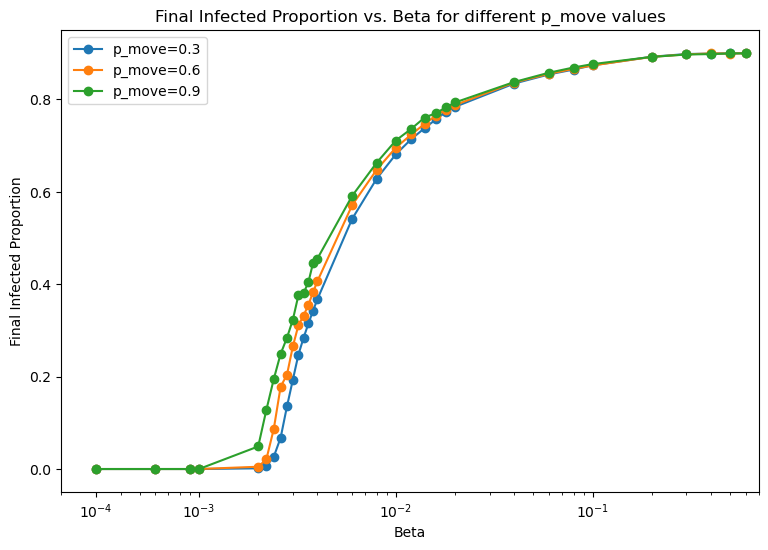

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

class SISModel:
    def __init__(self, N, population_per_patch, beta, mu, 
                 p, timesteps, initial_infected, alpha, average_degree):
        self.N = N
        self.population_per_patch = population_per_patch
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.timesteps = timesteps
        self.initial_infected = initial_infected
        self.average_degree = average_degree

        self.patches = np.zeros((N, population_per_patch))
        self.infection_history = np.zeros((timesteps, N))
        self.rho = np.zeros(N)  # 先初始化 self.rho

        self.G = nx.watts_strogatz_graph(N, 4, 0.8)

        # 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

        self._initialize_patches()

    def _initialize_patches(self):
        for i in range(self.N):
            infected_indices = np.random.choice(self.population_per_patch, self.initial_infected, replace=False)
            self.patches[i, infected_indices] = 1
            # get initial rho of each patch
            self.rho[i] = np.sum(self.patches[i]) / self.population_per_patch

    def _get_Pi_i(self):
        # 计算Πi
        R_i = np.zeros(self.N)
        D_i = np.zeros(self.N)
        P_i = np.zeros(self.N)
        Pi_i = np.zeros(self.N)
        new_rho = np.zeros(self.N)
        # 计算每个patch中的感染率
        for i in range(self.N):
            R_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.average_degree * self.rho[j] for j in range(self.N)]))
            D_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.population_per_patch * self.rho[i] *0.9 +
                                            np.sum([self.p * self.C[j, i] * self.population_per_patch * self.rho[j] for j in 
                                            range(self.N)]))
            P_i[i] = self.alpha * R_i[i] + (1 - self.alpha) * D_i[i]
            # Πi = infection_probabilities
        for i in range(self.N):
            Pi_i[i] = (1 - self.p) * P_i[i] + self.p * np.sum([self.C[i, j] * P_i[j] for j in range(self.N)])
            new_rho[i] = (1 - self.mu) * self.rho[i] + (1 - self.rho[i]) * Pi_i[i]
        # 更新rho
        self.Pi_i = Pi_i
        self.rho = new_rho
        return Pi_i

    def _infection_process(self, patch_index, current_patch):

        for j in range(self.population_per_patch):
            if current_patch[j] == 0 and np.random.rand() < self.Pi_i[patch_index]:
                current_patch[j] = 1
        return current_patch

    def _recovery_process(self, current_patch):
        for j in range(self.population_per_patch):
            if current_patch[j] == 1 and np.random.rand() < self.mu:
                current_patch[j] = 0
        return current_patch

    def run_simulation(self):
        self.average_infection_history = np.zeros(self.timesteps)  # 新增记录平均感染个体数量
        for t in range(self.timesteps):
            self._get_Pi_i()
            for i in range(self.N):
                current_patch = self.patches[i]
                current_patch = self._infection_process(i, current_patch)
                current_patch = self._recovery_process(current_patch)
                
                self.patches[i] = current_patch
                self.infection_history[t, i] = np.sum(current_patch) / self.population_per_patch  # 比例而不是数量
            # 记录每个时间步的平均感染个体比例
            self.average_infection_history[t] = np.mean(self.infection_history[t, :])  

    def plot_results(self, average_results):
        plt.figure(figsize=(10, 6))
        plt.plot(average_results, label='Average Infected Proportion')
        plt.xlabel('Time')
        plt.ylabel('Proportion of Infected Individuals')
        plt.ylim(0, 1)  # 设置y轴范围
        plt.legend()
        plt.title('Metapopulation SIS Model Simulation')
        plt.grid(True)
        plt.show()

# 参数设置
N = 50
population_per_patch = 100
mu = 0.1

timesteps = 200
initial_infected = 1
alpha = 0.6
average_degree = 10
num_simulations = 3

beta_values = np.concatenate([
    np.arange(0.0003, 0.001, 0.0003),
    np.arange(0.001, 0.002, 0.001),
    np.arange(0.002, 0.003, 0.0002),
    np.arange(0.003, 0.004, 0.0002),
    np.arange(0.004, 0.01, 0.002),
    np.arange(0.01, 0.02, 0.002),
    np.arange(0.02, 0.1, 0.02),
    np.arange(0.1, 0.7, 0.1)
])

p_values = [0.3, 0.6, 0.9]
all_results = {}

for p in p_values:
    final_infected_proportions = []
    for beta in beta_values:
        all_simulation_results = np.zeros((num_simulations, timesteps))
        
        for i in range(num_simulations):
            model = SISModel(N=N, population_per_patch=population_per_patch, beta=beta,
                             mu=mu, p=p, timesteps=timesteps, initial_infected=initial_infected, alpha=alpha, average_degree=average_degree)
            model.run_simulation()
            all_simulation_results[i, :] = model.average_infection_history
        
        # 计算时间步150到200之间的平均感染比例
        final_infected_proportion = np.mean(all_simulation_results[:, 150:200])
        final_infected_proportions.append(final_infected_proportion)

    # 将结果保存到CSV文件
    results_df = pd.DataFrame({
        'beta': beta_values,
        'final_infected_proportion': final_infected_proportions
    })
    results_df.to_csv(f'../data/MC_p_{p}.csv', index=False)
    
    # 记录结果用于绘图
    all_results[p] = final_infected_proportions

# 绘制结果
plt.figure(figsize=(9, 6))
for p in p_values:
    plt.plot(beta_values, all_results[p], marker='o', label=f'p_move={p}')
plt.xlabel('Beta')
plt.ylabel('Final Infected Proportion')
plt.xscale("log")
plt.yscale("linear")
plt.ylim(-0.05, 0.95)  # 设置y轴范围
plt.yticks(np.arange(0.0, 0.95, 0.2))
plt.xticks([0.0003, 0.001, 0.01, 0.1], ["$10^{-4}$", "$10^{-3}$", "$10^{-2}$", "$10^{-1}$"])
plt.xlim(0.0002, 0.7)  # 设置x轴范围
plt.title('Final Infected Proportion vs. Beta for different p_move values')
plt.legend()
plt.show()
